# Cat vs Dog CNN + Mission Control 🐱🐕
Building a CNN from scratch, tracking every experiment with W&B, and comparing against a pretrained ResNet-18.

|Item|Detail|
|---|---|
| **Dataset** | microsoft/cats_vs_dogs (23,410 images) |
| **Approach** | Scratch CNN → W&B baseline → Bayesian sweep → ResNet-18 transfer learning|
| **Stack** | PyTorch, torchvision, Weights & Biases, HuggingFace datasets |

---

## 1. Setup & Imports

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Total dataset size :  23410
Using (cpu/gpu) : cuda
Sample Image (Awww):-


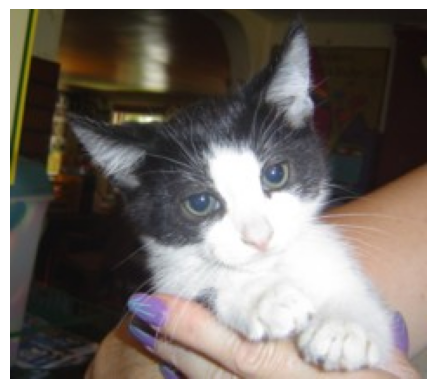

In [9]:
import random 
import numpy as np
import matplotlib.pyplot as plt
import wandb

# Only needed if running on Colab gpu, since we need to upload the file to access it
from google.colab import drive
drive.mount("/content/drive")

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms
from torchvision.models import ResNet18_Weights

from datasets import load_dataset

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# Change according to your case
CHECKPOINT = "/content/drive/MyDrive/best-params.pth"
RESNET_CHECKPOINT = "/content/drive/MyDrive/best-resnet.pth"

wandb.login()

raw_data = load_dataset("microsoft/cats_vs_dogs")
raw_data = raw_data['train']

print('Total dataset size : ', raw_data.num_rows)
print(f"Using (cpu/gpu) : {DEVICE}")
print("Sample Image (Awww):-")
plt.axis("off")
plt.imshow(raw_data[362]['image'])



## 2. Data Loading & Splits
70% train, 10% validation, 20% test.  

In [10]:
def set_seed(seed=37):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(37)

train_test_split = raw_data.train_test_split(test_size = 0.2, seed = 37)
train_val_split = train_test_split['train'].train_test_split(test_size = 0.125, seed = 37)

train_raw = train_val_split['train']
val_raw = train_val_split['test']
test_raw = train_test_split['test']

print(f"Training set size: {len(train_raw)}   (70%)")
print(f"Validation set size: {len(val_raw)}  (10%)")
print(f"Test set size: {len(test_raw)}        (20%)")

Training set size: 16387   (70%)
Validation set size: 2341  (10%)
Test set size: 4682        (20%)


## 3. Custom Dataset Class
Wraps the HuggingFace dataset in a PyTorch `Dataset` so `DataLoader` can batch, shuffle, and load it in parallel.

In [11]:
class cat_dog_dataset(Dataset):
    def __init__(self, hf_split, transform):
        self.data = hf_split
        self.transform = transform

    def __len__(self):
        return len(self.data)
    
    def __getitem__(self, index):
        item = self.data[index]
        image = item['image']
        label = item['labels']

        if image.mode != 'RGB':
            image = image.convert("RGB")

        if self.transform:
            image = self.transform(image)
        
        return image, label

## 4. DataLoaders
Training images get augmented (random crop, flip, color jitter) to prevent overfitting.  
Validation and test images get plain resizing only

In [12]:
def get_loaders(batch_size = 32, img_size = 64):
    train_transforms = transforms.Compose([
        transforms.Resize((img_size+20, img_size+20)),
        transforms.RandomCrop(img_size),
        transforms.RandomHorizontalFlip(),
        transforms.ColorJitter(brightness = 0.2, contrast = 0.2),
        transforms.ToTensor(),
        transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
    ])

    val_test_transforms = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
    ])

    train = cat_dog_dataset(train_raw, transform = train_transforms)
    validation = cat_dog_dataset(val_raw, transform = val_test_transforms)
    test = cat_dog_dataset(test_raw, transform = val_test_transforms)
    
    train_loader = DataLoader(train, batch_size = batch_size, pin_memory = True, shuffle = True, num_workers = 2)
    val_loader = DataLoader(validation, batch_size = batch_size, pin_memory = True, shuffle = True, num_workers = 2)
    test_loader = DataLoader(test, batch_size = batch_size, pin_memory = True, shuffle = True, num_workers = 2)

    return train_loader, val_loader, test_loader
    

## 5. CNN Architecture
A 3-block CNN, each block: Conv → BatchNorm → ReLU → Conv → BatchNorm → ReLU → MaxPool.  

In [13]:
class cat_dog_CNN(nn.Module):
    def __init__(self, num_filters = 32, dropout = 0.5):
        super().__init__()

        # starting with (batch_size, 3, 64, 64)
        self.block1 = nn.Sequential(
            nn.Conv2d(3, num_filters, kernel_size = 3, padding = 1),
            nn.BatchNorm2d(num_filters),
            nn.ReLU(inplace = True),
            nn.Conv2d(num_filters, num_filters, kernel_size = 3, padding = 1),
            nn.BatchNorm2d(num_filters),
            nn.ReLU(inplace = True),
            nn.MaxPool2d(2,2),
            nn.Dropout2d(0.1)
        )

        # (batch_size, 32, 32, 32)
        self.block2 = nn.Sequential(
            nn.Conv2d(num_filters, num_filters * 2, kernel_size = 3, padding = 1),
            nn.BatchNorm2d(num_filters * 2),
            nn.ReLU(inplace = True),
            nn.Conv2d(num_filters * 2, num_filters * 2, kernel_size = 3, padding = 1),
            nn.BatchNorm2d(num_filters * 2),
            nn.ReLU(inplace = True),
            nn.MaxPool2d(2,2),
            nn.Dropout2d(0.1)
        )

        # (batch_size, 64, 16, 16)
        self.block3 = nn.Sequential(
            nn.Conv2d(num_filters * 2, num_filters * 4, kernel_size = 3, padding = 1),
            nn.BatchNorm2d(num_filters * 4),
            nn.ReLU(inplace = True),
            nn.Conv2d(num_filters * 4, num_filters * 4, kernel_size = 3, padding = 1),
            nn.BatchNorm2d(num_filters * 4),
            nn.ReLU(inplace = True),
            nn.MaxPool2d(2,2),
        )

        # (batch_size, 128, 8, 8)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(num_filters * 4 * 8 * 8, 512),
            nn.ReLU(inplace = True),
            nn.Dropout(dropout),
            nn.Linear(512, 2)
        )

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.classifier(x)

        return x
    
def get_CNN(num_filters = 32, dropout = 0.5):
    model = cat_dog_CNN(num_filters = num_filters, dropout = dropout)
    #AI generated
    params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f'Parameters: {params:,}')
    return model

## 6. Training & Evaluation Functions

In [14]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss, correct_predictions, total_seen = 0, 0, 0,

    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        preds = outputs.argmax(dim = 1)
        correct_predictions += (preds == labels).sum().item()
        total_seen += labels.size(0)

    return total_loss / total_seen, correct_predictions / total_seen

def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct_predictions, total_seen = 0, 0, 0,

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            outputs = model(images)
            loss = criterion(outputs, labels)
            total_loss += loss.item() * images.size(0)
            preds = outputs.argmax(dim = 1)
            correct_predictions += (preds == labels).sum().item()
            total_seen += labels.size(0)
            
    return total_loss / total_seen, correct_predictions / total_seen

## 7. W&B Logging & Full Training Loop
`wandb.init()` starts a run, `wandb.log()` sends metrics each epoch, `wandb.watch()` tracks gradients.  
Best checkpoint saved whenever validation accuracy improves

In [15]:
def log_sample_predictions(model, loader, num_images = 16):
    model.eval()
    classes = ['cat', 'dog']
    logged = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(DEVICE)
            outputs = model(images)
            probs = torch.softmax(outputs, dim = 1)
            preds = outputs.argmax(dim = 1)

            for i in range(len(images)):
                if len(logged) >= num_images:
                    break
                
                img = img * 0.5 + 0.5
                img = images[i].cpu().permute(1, 2, 0).numpy().clip(0, 1)

                true = classes[labels[i].item()]
                pred = classes[preds[i].item()]
                conf = probs[i][preds[i]].item()
                color = '✓' if true == pred else '✗'
                caption = f'{color} True: {true} | Pred: {pred} ({conf:.0%})'
                logged.append(wandb.Image(img, caption=caption))

            if len(logged) >= num_images:
                break

    wandb.log({'predictions' : logged})


def train(config = None):
    with wandb.init(project = 'cat-vs-dog', name = 'cat-dog', config = config, settings=wandb.Settings(console="off", silent=True)):
        cfg = wandb.config

        train_loader, val_loader, test_loader = get_loaders(batch_size = cfg.batch_size, img_size = 64) #Note: both cfg.batch_size and cfg['batch_size'] work
        model = get_CNN(num_filters = cfg.num_filters, dropout = cfg.dropout).to(DEVICE)
        criterion = nn.CrossEntropyLoss()
        optimizer = optim.Adam(model.parameters(), lr = cfg.learning_rate, weight_decay = cfg.weight_decay)
        scheduler = optim.lr_scheduler.StepLR(optimizer, step_size= 5, gamma = 0.5) 
        wandb.watch(model, criterion, log = 'gradients', log_freq = 100)

        best_val_acc = 0 

        for epoch in range(cfg.epochs):
            train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer)
            val_loss, val_acc = evaluate(model, val_loader, criterion)
            scheduler.step()

            wandb.log({
                'epoch' : epoch + 1,
                'train_loss': train_loss,
                'train_accuracy' : train_acc,
                'val_loss' : val_loss,
                'val_accuracy' : val_acc
            })

            print(f'Ep {epoch+1:3}/{cfg.epochs} | '
                  f'train loss {train_loss:.4f} acc {train_acc:.4f} | '
                  f'val loss {val_loss:.4f} acc {val_acc:.4f}')
            
            if val_acc > best_val_acc:
                best_val_acc = val_acc
                torch.save({
                    'epoch' : epoch + 1,
                    'model_state' : model.state_dict(),
                    'val_acc' : val_acc,
                    'config' : dict(cfg)
                }, CHECKPOINT)
                print(f'  ✓ Best so far: {val_acc:.4f}')
        
        log_sample_predictions(model, val_loader)

        artifact = wandb.Artifact('cat-dog-classifier', type = 'model')
        artifact.add_file(CHECKPOINT)
        wandb.log_artifact(artifact)

        print(f'\nFinal best val acc: {best_val_acc:.4f}')

## 8. Baseline Run
Single training run with sensible default hyperparameters to establish a performance baseline.

In [ ]:
baseline_config = {
    'learning_rate': 1e-3,
    'batch_size':    32,
    'num_filters':   32,
    'dropout':       0.5,
    'weight_decay':  1e-4,
    'lr_step':       5,
    'epochs':        15,
    'model_type':    'scratch_cnn'
}

train(baseline_config)

Parameters: 9,537,346
Ep   1/15 | train loss 1.0318 acc 0.5294 | val loss 0.6815 acc 0.5694
  ✓ Best so far: 0.5694
Ep   2/15 | train loss 0.6836 acc 0.5590 | val loss 0.6674 acc 0.5784
  ✓ Best so far: 0.5784
Ep   3/15 | train loss 0.6734 acc 0.5836 | val loss 0.6551 acc 0.6514
  ✓ Best so far: 0.6514
Ep   4/15 | train loss 0.6766 acc 0.5814 | val loss 0.6257 acc 0.6642
  ✓ Best so far: 0.6642
Ep   5/15 | train loss 0.6672 acc 0.5945 | val loss 0.6144 acc 0.6484
Ep   6/15 | train loss 0.6288 acc 0.6432 | val loss 0.5925 acc 0.6843
  ✓ Best so far: 0.6843
Ep   7/15 | train loss 0.6180 acc 0.6549 | val loss 0.5976 acc 0.6937
  ✓ Best so far: 0.6937
Ep   8/15 | train loss 0.6017 acc 0.6699 | val loss 0.5545 acc 0.7219
  ✓ Best so far: 0.7219
Ep   9/15 | train loss 0.5800 acc 0.6986 | val loss 0.5856 acc 0.7129
Ep  10/15 | train loss 0.5471 acc 0.7295 | val loss 0.5353 acc 0.7296
  ✓ Best so far: 0.7296
Ep  11/15 | train loss 0.5057 acc 0.7616 | val loss 0.4616 acc 0.7877
  ✓ Best so far:

## 9. Hyperparameter Sweep
Bayesian search over Hyperparameters (20 trials)

In [23]:
sweep_config = {
    'method' : 'bayes',
    'metric' : {
        'name' : 'val/acc',
        'goal' : 'maximize'
    },
    'parameters' : {
        'learning_rate' : {
            'distribution' : 'log_uniform_values',
            'min' : 1e-4,
            'max' : 1e-2
        },
        'num_filters' : {
            'values' : [16,32,64]
        },
        'dropout' : {
            'values' : [0.2, 0.3, 0.4, 0.5, 0.6]
        },
        'batch_size' : {
            'values' : [16, 32, 64, 128]
        },
        'weight_decay': {
            'distribution': 'log_uniform_values',
            'min': 1e-6,
            'max': 1e-3
        },
        'lr_step': {
            'values': [3, 5, 8]
        },
        # Fixed — not swept
        'epochs':      {'value': 15},
        'model_type':  {'value': 'scratch_cnn'}
    }
}

sweep_id = wandb.sweep(sweep_config, project='cat-vs-dog')
print(f"Sweep ID: {sweep_id}")
wandb.agent(sweep_id, function=train, count=20)

Create sweep with ID: k4xj91qm
Sweep URL: https://wandb.ai/kushagra081207-manipal/cat-vs-dog/sweeps/k4xj91qm
Sweep ID: k4xj91qm
Parameters: 9,537,346
Ep   1/15 | train loss 0.6350 acc 0.6482 | val loss 0.5977 acc 0.6818
  ✓ Best so far: 0.6818
Ep   2/15 | train loss 0.5453 acc 0.7234 | val loss 0.5123 acc 0.7441
  ✓ Best so far: 0.7441
Ep   3/15 | train loss 0.4767 acc 0.7727 | val loss 0.4225 acc 0.8035
  ✓ Best so far: 0.8035
Ep   4/15 | train loss 0.4251 acc 0.8027 | val loss 0.3844 acc 0.8193
  ✓ Best so far: 0.8193
Ep   5/15 | train loss 0.3818 acc 0.8280 | val loss 0.3273 acc 0.8573
  ✓ Best so far: 0.8573
Ep   6/15 | train loss 0.3252 acc 0.8559 | val loss 0.2955 acc 0.8680
  ✓ Best so far: 0.8680
Ep   7/15 | train loss 0.3019 acc 0.8708 | val loss 0.2807 acc 0.8731
  ✓ Best so far: 0.8731
Ep   8/15 | train loss 0.2847 acc 0.8783 | val loss 0.2619 acc 0.8851
  ✓ Best so far: 0.8851
Ep   9/15 | train loss 0.2653 acc 0.8880 | val loss 0.2529 acc 0.8851
Ep  10/15 | train loss 0.252

## 10. Load Best Model & Predict
Load the best checkpoint from the sweep. `predict_your_image` runs inference on your own photos.

Best model details:-
Epoch: 15
Val acc: 0.9137
Config: {'batch_size': 32, 'dropout': 0.3, 'epochs': 15, 'learning_rate': 0.00027619331820394414, 'lr_step': 5, 'model_type': 'scratch_cnn', 'num_filters': 64, 'weight_decay': 8.943883055563106e-05}
Parameters: 9,537,346


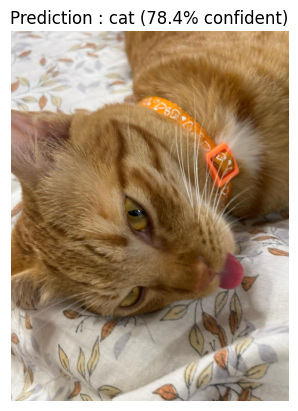

In [17]:
def load_best_model():
    checkpoint = torch.load(CHECKPOINT, map_location = DEVICE)
    cfg = checkpoint['config']

    print("Best model details:-")
    print(f"Epoch: {checkpoint['epoch']}")
    print(f"Val acc: {checkpoint['val_acc']:.4f}")
    print(f"Config: {cfg}")

    model = get_CNN(num_filters = cfg['num_filters'], dropout = cfg['dropout'])

    model.load_state_dict(checkpoint['model_state'])
    model.to(DEVICE)
    model.eval()

    return model

def predict_your_image(model, image_path):
    from PIL import Image
    
    model.eval()

    transform = transforms.Compose([
        transforms.Resize((64, 64)),
        transforms.ToTensor(),
        transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
    ])

    img = Image.open(image_path).convert('RGB')
    tensor = transform(img).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        output = model(tensor)
        prob = torch.softmax(output, dim = 1)
        pred = output.argmax(dim=1).item()

    classes = ['cat', 'dog']
    label = classes[pred]
    conf = prob[0][pred].item()

    plt.imshow(img)
    plt.title(f'Prediction : {label} ({conf:.1%} confident)')
    plt.axis('off')
    plt.show()

best_model = load_best_model()
predict_your_image(best_model, '/content/drive/MyDrive/my-cat.jpeg')

## 11. ResNet-18 — Transfer Learning
Load a pretrained ResNet-18 (trained on ImageNet's 1.4M images), freeze the backbone, and replace the final layer for binary classification.  

In [18]:
def build_resnet(freeze_backbone = True):
    model = models.resnet18(weights = ResNet18_Weights.DEFAULT)

    if freeze_backbone:
        for param in model.parameters():
            param.requires_grad = False

    second_last_layer_params = model.fc.in_features
    model.fc = nn.Linear(second_last_layer_params, 2)

    return model.to(DEVICE)

def train_resnet(config = None):

    with wandb.init(project='cat-vs-dog', name='resnet18-frozen', config = config, settings=wandb.Settings(console="off", silent=True)):
        cfg = wandb.config

        train_transform = transforms.Compose([
            transforms.Resize((256, 256)),
            transforms.RandomCrop(224),
            transforms.RandomHorizontalFlip(),
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
        ])

        val_test_transform = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
        ])

        train_dataset = cat_dog_dataset(train_raw, transform = train_transform)
        val_dataset   = cat_dog_dataset(val_raw,   transform = val_test_transform)

        train_loader = DataLoader(train_dataset, batch_size=cfg.batch_size,
                                   shuffle=True,  num_workers=2, pin_memory=True)
        val_loader   = DataLoader(val_dataset,   batch_size=cfg.batch_size,
                                   shuffle=False, num_workers=2, pin_memory=True)

        model = build_resnet(freeze_backbone = cfg.freeze_backbone)
        criterion = nn.CrossEntropyLoss()
        optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()) , lr = cfg.learning_rate, weight_decay = cfg.weight_decay)
        scheduler = optim.lr_scheduler.StepLR(optimizer, step_size = cfg.lr_step, gamma = 0.5)

        best_val_acc = 0

        for epoch in range(cfg.epochs):
            train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer)
            val_loss, val_acc = evaluate(model, val_loader, criterion)
            scheduler.step()

            wandb.log({
                'epoch' : epoch + 1,
                'train/loss' : train_loss,
                'train/acc' : train_acc,
                'val/loss' : val_loss,
                'val/acc' : val_acc,
            })

            print(f'Ep {epoch+1:3}/{cfg.epochs} | '
                  f'train acc {train_acc:.4f} | val acc {val_acc:.4f}')
            
            if val_acc > best_val_acc:
                best_val_acc = val_acc
                torch.save({
                    'epoch': epoch + 1,
                    'model_state': model.state_dict(),
                    'val_acc': val_acc,
                    'config': dict(cfg),
                    'model_type': 'resnet18'
                }, RESNET_CHECKPOINT)
                print(f'  ✓ Best: {val_acc:.4f}')

        print(f'\nBest val acc: {best_val_acc:.4f}')

resnet_config = {
    'learning_rate':   1e-4,
    'batch_size':      32,
    'freeze_backbone': True,
    'weight_decay':    1e-4,
    'lr_step':         5,
    'epochs':          10,
    'model_type':      'resnet18'
}

train_resnet(resnet_config)      

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 196MB/s]


Ep   1/10 | train acc 0.8986 | val acc 0.9586
  ✓ Best: 0.9586
Ep   2/10 | train acc 0.9595 | val acc 0.9633
  ✓ Best: 0.9633
Ep   3/10 | train acc 0.9659 | val acc 0.9658
  ✓ Best: 0.9658
Ep   4/10 | train acc 0.9687 | val acc 0.9722
  ✓ Best: 0.9722
Ep   5/10 | train acc 0.9688 | val acc 0.9688
Ep   6/10 | train acc 0.9692 | val acc 0.9692
Ep   7/10 | train acc 0.9705 | val acc 0.9710
Ep   8/10 | train acc 0.9725 | val acc 0.9735
  ✓ Best: 0.9735
Ep   9/10 | train acc 0.9712 | val acc 0.9714
Ep  10/10 | train acc 0.9718 | val acc 0.9735

Best val acc: 0.9735


## 12. Final Test Set Evaluation
Scratch CNN  V/S  ResNet-18

In [19]:
def evaluate_on_test():
    criterion = nn.CrossEntropyLoss()

    CNN_checkpoint = torch.load(CHECKPOINT, map_location=DEVICE)
    cnn_cfg = CNN_checkpoint['config']

    scratch_CNN = get_CNN(num_filters=cnn_cfg['num_filters'], dropout=cnn_cfg['dropout']).to(DEVICE)
    scratch_CNN.load_state_dict(CNN_checkpoint['model_state'])
    scratch_CNN.eval()

    _, _, cnn_test_loader = get_loaders(batch_size=32, img_size=64)

    cnn_test_loss, cnn_test_acc = evaluate(scratch_CNN, cnn_test_loader, criterion)

    print("SCRATCH CNN:-")
    print(f"Val acc (from training): {CNN_checkpoint['val_acc']:.2f}")
    print(f"Final Test acc: {cnn_test_acc:.2f}")
    print(f"Test loss: {cnn_test_loss:.2f}")
    print(f"Config: {cnn_cfg}")

    resnet_checkpoint = torch.load(RESNET_CHECKPOINT, map_location=DEVICE)
    resnet_cfg = resnet_checkpoint['config']

    resnet = build_resnet(freeze_backbone=resnet_cfg.get('freeze_backbone', True)).to(DEVICE)
    resnet.load_state_dict(resnet_checkpoint['model_state'])
    resnet.eval()

    resnet_test_transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])
    resnet_test_dataset = cat_dog_dataset(test_raw, transform=resnet_test_transform)
    resnet_test_loader  = DataLoader(resnet_test_dataset, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

    resnet_test_loss, resnet_test_acc = evaluate(resnet, resnet_test_loader, criterion)

    print()
    print("RESNET-18")
    print(f"Val acc (from training): {resnet_checkpoint['val_acc']:.4f}")
    print(f"Final Test acc: {resnet_test_acc:.4f}")
    print(f"Test loss: {resnet_test_loss:.4f}")
    print(f"Config: {resnet_cfg}")

    print()
    print(f"Scratch CNN test acc:  {cnn_test_acc:.4f}")
    print(f"ResNet-18 test acc:    {resnet_test_acc:.4f}")

evaluate_on_test()

Parameters: 9,537,346
SCRATCH CNN:-
Val acc (from training): 0.91
Final Test acc: 0.91
Test loss: 0.22
Config: {'batch_size': 32, 'dropout': 0.3, 'epochs': 15, 'learning_rate': 0.00027619331820394414, 'lr_step': 5, 'model_type': 'scratch_cnn', 'num_filters': 64, 'weight_decay': 8.943883055563106e-05}

RESNET-18
Val acc (from training): 0.9735
Final Test acc: 0.9769
Test loss: 0.0637
Config: {'learning_rate': 0.0001, 'batch_size': 32, 'freeze_backbone': True, 'weight_decay': 0.0001, 'lr_step': 5, 'epochs': 10, 'model_type': 'resnet18'}

Scratch CNN test acc:  0.9141
ResNet-18 test acc:    0.9769
